In [1]:
# Standard Libraries

import os
import gc
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")


# Data Manipulation

import numpy as np
import pandas as pd


# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")

# Machine Learning Models

import tensorflow as tf
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# Evaluation


from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# TensorFlow

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import regularizers

In [2]:
# Project Configuration

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

FIGSIZE = (12,6)

print("TensorFlow Version :", tf.__version__)
print("NumPy Version      :", np.__version__)
print("Pandas Version     :", pd.__version__)

TensorFlow Version : 2.21.0
NumPy Version      : 2.4.6
Pandas Version     : 3.0.5


In [30]:
from pathlib import Path
import joblib
from tensorflow.keras.models import load_model


DATA_DIR = Path("data/Training_Datasets")
RESULT_DIR = Path('Results')
CONFIG_DIR = Path("artifacts")

X_train_tree = pd.read_csv(DATA_DIR / "X_train_tree.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")

X_test_tree  = pd.read_csv(DATA_DIR / "X_test_tree.csv")
y_test  = pd.read_csv(DATA_DIR / "y_test.csv").squeeze("columns")

MODEL_DIR = Path("models")
lgbm_model = joblib.load(MODEL_DIR / "lightgbm.joblib")

all_val_results = pd.read_csv(RESULT_DIR/"all_models_results.csv")

# Final Evaluation on Hold-Out Test Set

# 14.1 Use the Validation Threshold

The threshold was already optimized on the validation set.

In [32]:
# Final Decision Threshold

FINAL_THRESHOLD = 0.216629

# 14.2 Predict Test Probabilities

In [6]:
# ============================================================
# Predict on Hold-Out Test Set
# ============================================================

test_prob = lgbm_model.predict_proba(
    X_test_tree
)[:, 1]

print(test_prob[:10])

[0.00055771 0.00672412 0.01464578 0.000616   0.00262645 0.0031105
 0.50451089 0.0007229  0.23813849 0.00079472]


# 14.3 Generate Final Predictions

In [7]:
test_pred = (
    test_prob >= FINAL_THRESHOLD
).astype(int)

In [11]:
test_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(88581,))

# 14.4 Final Metrics

In [12]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

test_metrics = {

    "Accuracy":
        accuracy_score(
            y_test,
            test_pred
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            y_test,
            test_pred
        ),

    "Precision":
        precision_score(
            y_test,
            test_pred,
            zero_division=0
        ),

    "Recall":
        recall_score(
            y_test,
            test_pred
        ),

    "F1":
        f1_score(
            y_test,
            test_pred
        ),

    "ROC_AUC":
        roc_auc_score(
            y_test,
            test_prob
        ),

    "PR_AUC":
        average_precision_score(
            y_test,
            test_prob
        )

}

test_metrics = pd.DataFrame(
    test_metrics,
    index=["LightGBM Test"]
)

display(test_metrics)

,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
LightGBM Test,0.964473,0.748662,0.490154,0.516705,0.503079,0.903455,0.523028


# 14.5 Classification Report

In [13]:
print(
    classification_report(
        y_test,
        test_pred
    )
)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     85498
           1       0.49      0.52      0.50      3083

    accuracy                           0.96     88581
   macro avg       0.74      0.75      0.74     88581
weighted avg       0.97      0.96      0.96     88581



# 14.6 Confusion Matrix

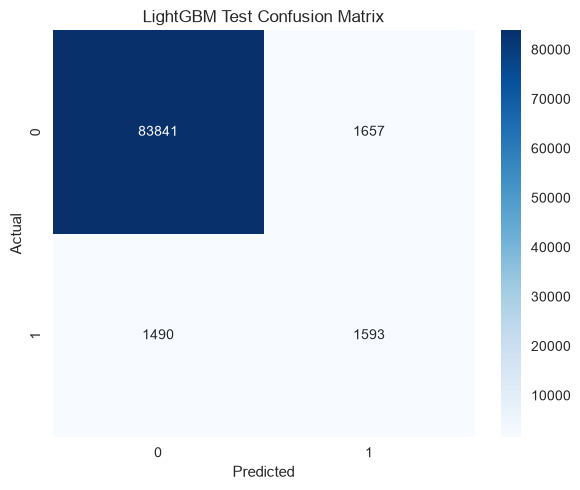

In [14]:
cm = confusion_matrix(
    y_test,
    test_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("LightGBM Test Confusion Matrix")

plt.tight_layout()

plt.show()

# 14.7 ROC Curve

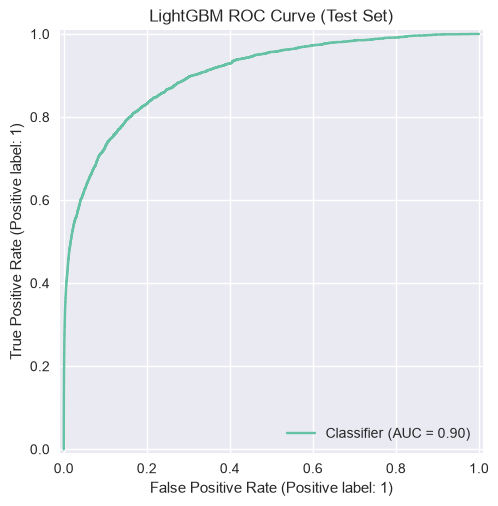

In [15]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    test_prob
)

plt.title("LightGBM ROC Curve (Test Set)")

plt.show()

# 14.8 Precision-Recall Curve

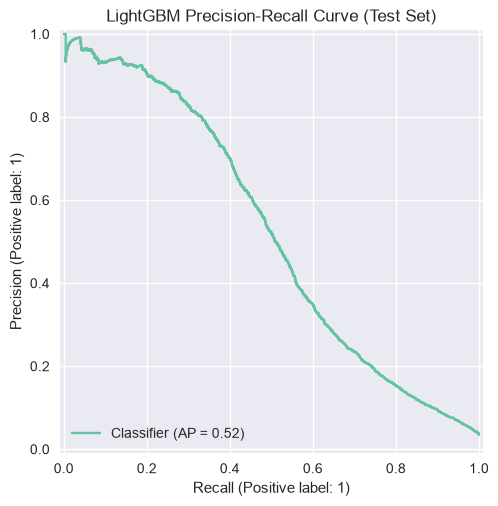

In [16]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_prob
)

plt.title("LightGBM Precision-Recall Curve (Test Set)")

plt.show()

For highly imbalanced fraud detection, the Precision-Recall curve is generally more informative than ROC alone because it emphasizes performance on the minority (fraud) class.

# 14.9 Validation vs Test Comparison

One thing missing from many notebooks is checking whether the model generalizes.

In [23]:
comparison = pd.DataFrame({

    "Validation": [

        all_val_results.loc[
            all_val_results["Model"]=="LightGBM",
            "ROC_AUC"
        ].iloc[0],

        all_val_results.loc[
            all_val_results["Model"]=="LightGBM",
            "PR_AUC"
        ].iloc[0],

        all_val_results.loc[
            all_val_results["Model"]=="LightGBM",
            "F1"
        ].iloc[0]

    ],

    "Test": [

        test_metrics.loc[
            "LightGBM Test",
            "ROC_AUC"
        ],

        test_metrics.loc[
            "LightGBM Test",
            "PR_AUC"
        ],

        test_metrics.loc[
            "LightGBM Test",
            "F1"
        ]

    ]

},

index=[

    "ROC-AUC",

    "PR-AUC",

    "F1"

])

display(comparison)

,Validation,Test
ROC-AUC,0.918354,0.903455
PR-AUC,0.589560,0.523028
F1,0.570863,0.503079


# 14.10 Generalization Gap

In [24]:
comparison["Gap"] = (
    comparison["Validation"] -
    comparison["Test"]
)

comparison["%acc"] = (
    (comparison["Test"] /
    comparison["Validation"])*100
)

display(comparison)

,Validation,Test,Gap,%acc
ROC-AUC,0.918354,0.903455,0.014900,98.377553
PR-AUC,0.589560,0.523028,0.066532,88.715034
F1,0.570863,0.503079,0.067784,88.126019


Interpretation:

- Gap < 0.01 → Excellent generalization
- 0.01–0.03 → Normal variance
- > 0.05 → Possible overfitting or distribution shift

# 14.11 Calibration Analysis

Fraud detection systems often need well-calibrated probabilities, not just good rankings. Before deployment, it's useful to check whether predicted probabilities correspond to observed fraud rates.

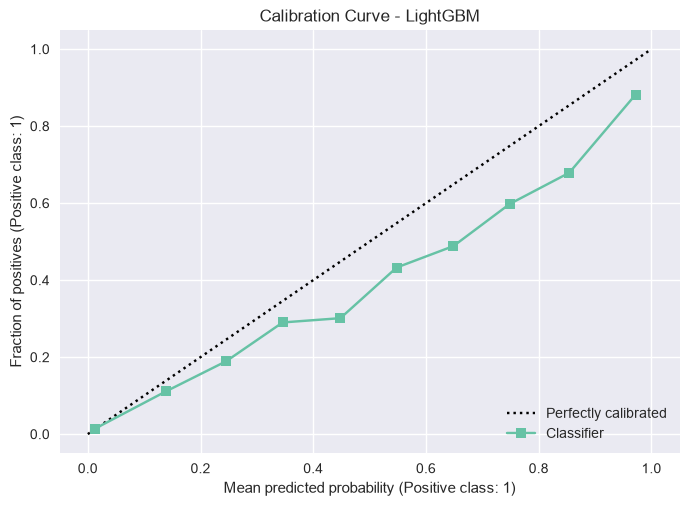

In [25]:
from sklearn.calibration import CalibrationDisplay

CalibrationDisplay.from_predictions(
    y_test,
    test_prob,
    n_bins=10
)

plt.title("Calibration Curve - LightGBM")

plt.show()

Probability calibration is important because decision thresholds and downstream business actions depend on the reliability of predicted probabilities, not only on ranking performance.

# 15.4 Save Metadata

Saving metadata makes experiments reproducible.


In [29]:
metadata = {

    "model_name": "LightGBM",

    "dataset": "IEEE-CIS Fraud Detection",

    "random_state": RANDOM_STATE,

    "validation_threshold": FINAL_THRESHOLD,

    "validation_pr_auc":
        all_val_results.loc[
            all_val_results.Model=="LightGBM",
            "PR_AUC"
        ].iloc[0],

    "test_pr_auc":
        test_metrics.loc[
            "LightGBM Test",
            "PR_AUC"
        ],

    "features":
        list(X_train_tree.columns)

}

In [31]:
import json

with open(
    CONFIG_DIR / "metadata.json",
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print("✓ Metadata saved.")

✓ Metadata saved.
